# Exercise 4: MLOps

MNIST digit classification with a one-hidden-layer network, tracked and tuned with Weights & Biases (W&B).

## Setup
Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import wandb
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from torchvision import datasets
from dotenv import load_dotenv, find_dotenv

Load `WANDB_API_KEY` from the `.env` file in the repository root, so W&B logs in automatically, and silence W&B's console messages.

In [2]:
load_dotenv(find_dotenv(usecwd=True))
os.environ["WANDB_SILENT"] = "true"
print("W&B key found:", "WANDB_API_KEY" in os.environ)

W&B key found: True


All training settings live in `CFG`

In [3]:
CFG = dict(project="dl-mnist", n_train=50000, n_val=10000, hidden=42, epochs=10, batch_size=64, lr=1e-3, seed=0, sweep_runs=20)

Select device

In [4]:
cuda_available = torch.cuda.is_available()
mps_available = torch.backends.mps.is_available()
device = os.environ.get("DEVICE") or ("cuda" if cuda_available else "mps" if mps_available else "cpu")
print("device:", device)

device: cpu


Helper method for seed setting

In [5]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

Create folder for results

In [6]:
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Data
MNIST is downloaded once and kept in memory as normalised, flattened tensors.

In [7]:
def load_mnist(train):
    ds = datasets.MNIST("data", train=train, download=True)
    X = (ds.data.float() / 255 - 0.1307) / 0.3081

    return TensorDataset(X.flatten(1), ds.targets)

full_train, test_ds = load_mnist(train=True), load_mnist(train=False)

The official training set is split into training and validation sets, so the sweep never looks at the test set.

In [8]:
n_rest = len(full_train) - CFG["n_train"] - CFG["n_val"]
split_gen = torch.Generator().manual_seed(0)
train_ds, val_ds, _ = random_split(full_train, [CFG["n_train"], CFG["n_val"], n_rest], generator=split_gen)
print(f"train {len(train_ds)}, validation {len(val_ds)}, test {len(test_ds)}")

train 50000, validation 10000, test 10000


## Model
One hidden ReLU layer and 10 outputs (the softmax is inside the cross-entropy loss).

In [9]:
class MLP(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.model = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))

    def forward(self, x): return self.model(x)

print(MLP(CFG["hidden"]))

MLP(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=42, bias=True)
    (1): ReLU()
    (2): Linear(in_features=42, out_features=10, bias=True)
  )
)


## Training and evaluation
Mini-batches over a dataset give its mean loss and accuracy.

In [10]:
@torch.no_grad()
def evaluate(model, ds, batch_size=10000):
    model.eval()
    total_loss, correct = 0.0, 0
    for X, y in DataLoader(ds, batch_size=batch_size):
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()

    return total_loss / len(ds), correct / len(ds)

## 2. Training pipeline with W&B logging
`wandb.init` starts a run and stores its settings, `wandb.log` sends each epoch's train and validation metrics to the dashboard, and `run.summary` stores the test result computed once after training.

In [11]:
def train(cfg):
    history = []
    with wandb.init(project=cfg["project"], config=cfg) as run:
        cfg = run.config
        set_seed(cfg.seed)
        model = MLP(cfg.hidden).to(device)
        loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True)
        opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
        loss_fn = nn.CrossEntropyLoss()

        for epoch in range(1, cfg.epochs + 1):
            model.train()
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                loss = loss_fn(model(X), y)
                opt.zero_grad()
                loss.backward()
                opt.step()

            row = {"epoch": epoch}
            for name, ds in [("train", train_ds), ("val", val_ds)]:
                row[f"{name}_loss"], row[f"{name}_acc"] = evaluate(model, ds)
            wandb.log(row)
            history.append(row)

        run.summary["test_loss"], run.summary["test_acc"] = evaluate(model, test_ds)
        print(f"lr={cfg.lr:.1e}  batch={cfg.batch_size:<3}  hidden={cfg.hidden:<3}  "
              f"val_loss={row['val_loss']:.4f}  val_acc={row['val_acc']:.4f}  test_acc={run.summary['test_acc']:.4f}")

    return model, pd.DataFrame(history)

Train the baseline network with 42 hidden units.

In [12]:
model, hist = train(CFG)
hist.round(4)

lr=1.0e-03  batch=64   hidden=42   val_loss=0.1178  val_acc=0.9657  test_acc=0.9719


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.2153,0.9359,0.2346,0.9306
1,2,0.1615,0.9514,0.1860,0.9447
2,3,0.1161,0.9652,0.1509,0.9561
3,4,0.0893,0.9736,0.1282,0.9609
4,5,0.0801,0.9763,0.1296,0.9619
5,6,0.0744,0.9769,0.1246,0.9630
6,7,0.0594,0.9821,0.1204,0.9635
7,8,0.0563,0.9828,0.1220,0.9618
8,9,0.0504,0.9843,0.1250,0.9650
9,10,0.0424,0.9876,0.1178,0.9657


The same train and validation curves as on the W&B dashboard, saved for the report.

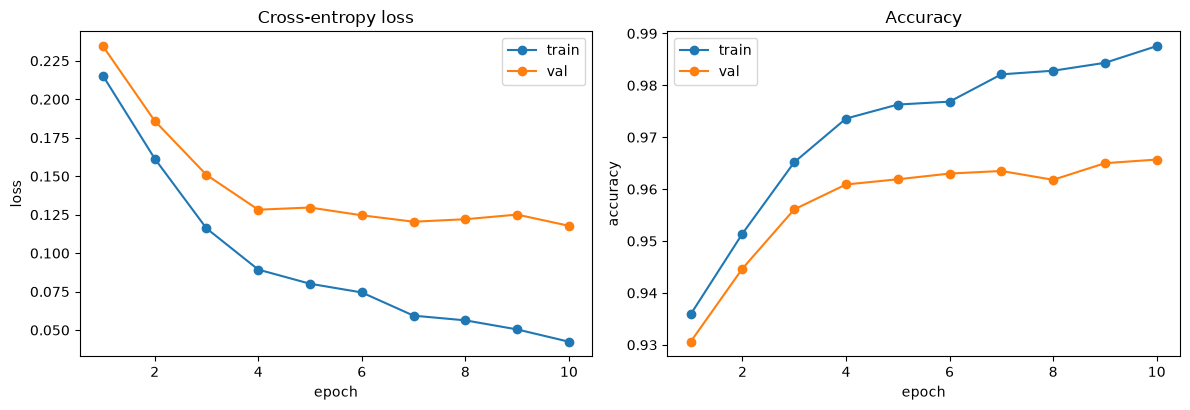

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name in ["train", "val"]:
    axes[0].plot(hist.epoch, hist[f"{name}_loss"], marker="o", label=name)
    axes[1].plot(hist.epoch, hist[f"{name}_acc"], marker="o", label=name)

axes[0].set(title="Cross-entropy loss", xlabel="epoch", ylabel="loss")
axes[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
for ax in axes: ax.legend()

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/mnist_baseline.png", dpi=150)

plt.show()

## 3. Hyperparameter sweep
Random search over learning rate (log scale, as its effect spans orders of magnitude), batch size and hidden units, picking the best run by validation loss.

In [14]:
sweep_config = {
    "method": "random",
    "metric": {"name": "val_loss", "goal": "minimize"},
    "parameters": {
        "lr": {"distribution": "log_uniform_values", "min": 1e-4, "max": 1e-1},
        "batch_size": {"values": [32, 64, 128, 256]},
        "hidden": {"values": [16, 42, 128, 256]},
    },
}

Every sweep run calls the same `train` function, and W&B replaces the swept values in its config.

In [15]:
sweep_id = wandb.sweep(sweep_config, project=CFG["project"])
wandb.agent(sweep_id, lambda: train(CFG), count=CFG["sweep_runs"])

Create sweep with ID: oozapt0z
Sweep URL: https://forge.coreweave.com/wandb/juh6973-tampere-university/dl-mnist/sweeps/oozapt0z


lr=2.6e-03  batch=32   hidden=16   val_loss=0.2305  val_acc=0.9371  test_acc=0.9382


lr=2.9e-03  batch=256  hidden=256  val_loss=0.1212  val_acc=0.9754  test_acc=0.9759


lr=3.4e-04  batch=256  hidden=128  val_loss=0.1102  val_acc=0.9682  test_acc=0.9689


lr=1.0e-04  batch=128  hidden=128  val_loss=0.1571  val_acc=0.9539  test_acc=0.9592


lr=7.8e-02  batch=256  hidden=42   val_loss=0.7106  val_acc=0.7696  test_acc=0.7694


... (11 outputs left out)

lr=1.4e-04  batch=128  hidden=128  val_loss=0.1359  val_acc=0.9599  test_acc=0.9640


lr=2.6e-02  batch=256  hidden=128  val_loss=0.2786  val_acc=0.9431  test_acc=0.9449


lr=2.5e-02  batch=256  hidden=256  val_loss=0.2203  val_acc=0.9480  test_acc=0.9525


lr=6.4e-03  batch=32   hidden=42   val_loss=0.2354  val_acc=0.9463  test_acc=0.9460


Fetch the final metrics of every sweep run from W&B.

In [16]:
api = wandb.Api()
sweep = api.sweep(f"{api.default_entity}/{CFG['project']}/{sweep_id}")
results = pd.DataFrame([
    {**{k: r.config[k] for k in ["lr", "batch_size", "hidden"]},
     **{k: r.summary.get(k) for k in ["val_loss", "val_acc", "test_loss", "test_acc"]}}
    for r in sweep.runs if r.state == "finished"
]).sort_values("val_loss").reset_index(drop=True)

The highlighted run has the lowest validation loss, and its test accuracy is the final, unbiased score.

In [17]:
highlight = lambda r: ["background-color: #c8f7c5; font-weight: bold" if r.name == 0 else ""] * len(r)
results.style.apply(highlight, axis=1).format({"lr": "{:.2e}"}, precision=4)

,lr,batch_size,hidden,val_loss,val_acc,test_loss,test_acc
0,3.42e-04,256,128,0.1102,0.9682,0.1030,0.9689
1,1.59e-03,64,256,0.1117,0.9765,0.1050,0.9758
2,2.94e-03,256,256,0.1212,0.9754,0.1122,0.9759
3,1.38e-04,128,128,0.1359,0.9599,0.1245,0.9640
4,5.88e-03,256,256,0.1501,0.9694,0.1607,0.9696
5,1.04e-04,128,128,0.1571,0.9539,0.1446,0.9592
6,5.56e-03,128,128,0.1668,0.9716,0.1483,0.9740
7,1.28e-04,128,42,0.2188,0.9372,0.2059,0.9401
8,8.61e-03,64,256,0.2218,0.9579,0.2257,0.9566
9,1.30e-04,32,16,0.2296,0.9336,0.2212,0.9361


## 4. Experimental setup and results

**Setup.** A 784-42-10 ReLU network was trained on 50k MNIST images with Adam and cross-entropy loss (10 epochs, batch size 64, lr = 1e-3), with 10k images held out for validation and the official 10k test set used once after training. All runs were logged to W&B, and a random sweep of 20 runs varied the learning rate (1e-4 to 1e-1, log scale), batch size (32–256) and hidden units (16–256), ranking runs by final validation loss.

**Why these parameters.** The learning rate is usually the most important setting for Adam, so it gets a wide log-scale range around the common default 1e-3. Hidden units set the model's capacity and are the natural thing to vary around the given 42. Batch size changes how noisy and how many the weight updates are, and it interacts with the learning rate.

**Baseline.** The baseline reaches 96.6 % validation and 97.2 % test accuracy. Validation loss stops improving after about 4 epochs while training loss keeps falling, so the network starts to overfit slightly.

**Sweep.**
- Learning rate matters most: around 0.07 training breaks down (17–77 % accuracy), 0.01–0.03 gives clearly worse results (94–95 %), and the good runs lie between 3e-4 and 3e-3.
- More hidden units help: 16 units stay at 91–94 %, while 128–256 units give the best runs (up to 97.6 % validation accuracy).
- Batch size has no clear effect of its own within the good learning-rate range.
- The lowest validation loss (lr = 3.4e-4, batch 256, 128 units: 96.8 % val / 96.9 % test accuracy) and the highest validation accuracy (lr = 1.6e-3, batch 64, 256 units: 97.7 % val / 97.6 % test) come from different runs with almost the same loss, so the choice of selection metric matters here.

**Careful conclusions.** A moderate learning rate (about 3e-4 to 3e-3) and a wider hidden layer (128+ units) seem to be the most useful changes, giving about 0.5 percentage points over the baseline. These conclusions are preliminary: each setting was run with one seed, the sweep has only 20 runs for 3 parameters, training is short (10 epochs, no learning-rate schedule), and differences below about 0.5 percentage points are likely within run-to-run noise.